---
title: "Konsep-regresi-linier-dalam-permodelan-karbon: Analisis_Regresi_Linier_Berganda.ipynb"
---


# **Analisis Regresi Linier Berganda dalam Pembuatan Model Pendugan Biomassa Berbasis Data Penginderaan Jauh dan Survei Lapangan Menggunakan Python**

**Penulis: Defani Arman Alfitriansyah**

Fakultas Kehutanan dan Lingkungan, Universitas Kuningan,
Tahun 2025


---



Analisis ini bertujuan untuk membangun model regresi linier berganda untuk memprediksi biomassa (AGC\_ton\_per\_ha) berdasarkan beberapa variabel independen: NDVI, IRECI, dan TRVI. Model regresi linier berganda menggambarkan hubungan linier antara variabel dependen dan beberapa variabel independen. Dalam kasus ini, biomassa (AGC\_ton\_per\_ha) adalah variabel dependen ($y$), dan NDVI, IRECI, serta TRVI adalah variabel independen ($x_1, x_2, x_3$). Rumus umum model regresi linier berganda adalah:

$$ y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_n x_n + \epsilon $$

Di mana:
- $y$ adalah variabel dependen (AGC\_ton\_per\_ha)
- $\beta_0$ adalah *intercept* (konstanta)
- $\beta_1, \beta_2, \dots, \beta_n$ adalah koefisien regresi untuk setiap variabel independen
- $x_1, x_2, \dots, x_n$ adalah variabel independen (NDVI, IRECI, TRVI)
- $\epsilon$ adalah *error term* (galat acak)

Langkah-langkah yang dilakukan dalam analisis ini meliputi:

1.  **Memuat Data**: Data biomassa, yang mencakup kolom ID, NDVI, IRECI, TRVI, dan AGC\_ton\_per\_ha, dimuat dari file Excel menggunakan library **pandas**. Pandas (`import pandas as pd`) adalah library fundamental dalam Python untuk manipulasi dan analisis data tabular, menyediakan struktur data seperti DataFrame yang memudahkan pengelolaan data.
2.  **Persiapan Data untuk Regresi**: Variabel independen (NDVI, IRECI, TRVI) dan variabel dependen (AGC\_ton\_per\_ha) dipisahkan dari DataFrame utama. Untuk analisis menggunakan library **statsmodels**, yang digunakan untuk analisis statistik yang lebih mendalam dibandingkan `sklearn.linear_model`, sebuah kolom konstanta dengan nilai 1 ditambahkan ke variabel independen. Penambahan konstanta ini ($X_{sm} = sm.add\_constant(X)$) memungkinkan model untuk menghitung *intercept*. Statsmodels (`import statsmodels.api as sm`) menyediakan berbagai model statistik dan hasil ringkasan yang detail.
3.  **Pelatihan Model Regresi**: Model regresi linier berganda dilatih menggunakan fungsi OLS (Ordinary Least Squares) dari library **statsmodels**. Metode OLS bertujuan untuk meminimalkan jumlah kuadrat *error* antara nilai aktual dan nilai prediksi. Proses pelatihan dilakukan dengan `model_sm = sm.OLS(y, X_sm).fit()`. Hasil dari proses *fitting* ini mencakup estimasi koefisien regresi ($\beta$ values), *p-value* untuk signifikansi setiap koefisien, dan statistik keseluruhan model.
4.  **Evaluasi Model dan Visualisasi**: Kinerja model dievaluasi menggunakan dua metrik utama: R-squared dan Root Mean Squared Error (RMSE).
    - **R-squared ($R^2$)**: Menunjukkan proporsi variabilitas dalam variabel dependen yang dapat dijelaskan oleh variabel independen dalam model. Nilai R-squared berkisar antara 0 hingga 1; nilai yang lebih tinggi menunjukkan model yang lebih baik dalam menjelaskan variabilitas data. Rumusnya adalah:
    $$ R^2 = 1 - \frac{\text{SSR}}{\text{SST}} $$
    Di mana SSR (Sum of Squares of Residuals) adalah jumlah kuadrat selisih antara nilai aktual dan prediksi, dan SST (Total Sum of Squares) adalah jumlah kuadrat selisih antara nilai aktual dan rata-rata nilai aktual.
    - **Root Mean Squared Error (RMSE)**: Mengukur rata-rata besar *error* antara nilai prediksi dan nilai aktual. RMSE dihitung sebagai akar kuadrat dari Mean Squared Error (MSE). Nilai RMSE yang lebih rendah menunjukkan *error* prediksi yang lebih kecil dan kinerja model yang lebih baik. Rumusnya adalah:
    $$ \text{RMSE} = \sqrt{\frac{1}{N} \sum_{i=1}^{N} (y_i - \hat{y}_i)^2} $$
    Di mana $N$ adalah jumlah observasi, $y_i$ adalah nilai aktual, dan $\hat{y}_i$ adalah nilai prediksi.
    Visualisasi perbandingan antara nilai aktual dan prediksi dibuat menggunakan scatter plot (`seaborn.scatterplot`) dengan garis diagonal (nilai aktual = nilai prediksi) sebagai referensi (`matplotlib.pyplot.plot`). Visualisasi ini membantu menilai seberapa dekat titik-titik data dengan garis referensi. **Matplotlib.pyplot** (`import matplotlib.pyplot as plt`) adalah library dasar untuk membuat grafik, sementara **Seaborn** (`import seaborn as sns`) menyediakan antarmuka tingkat tinggi untuk visualisasi statistik yang lebih menarik.
5.  **Analisis Korelasi**: Matriks korelasi antar variabel (kecuali kolom ID yang tidak relevan) dihitung menggunakan fungsi `.corr()` dari pandas. Matriks korelasi menampilkan koefisien korelasi Pearson antar setiap pasangan variabel. Koefisien korelasi ($r$) mengukur kekuatan dan arah hubungan linier antara dua variabel, dengan nilai berkisar antara -1 (korelasi negatif sempurna) hingga 1 (korelasi positif sempurna), dan 0 menunjukkan tidak ada korelasi linier.
**Koefisien Korelasi Pearson ($r$)** dihitung dengan rumus:

$$r = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{n} (x_i - \bar{x})^2} \sqrt{\sum_{i=1}^{n} (y_i - \bar{y})^2}}$$

dengan:
- $x_i$ = nilai variabel X ke-$i$
- $y_i$ = nilai variabel Y ke-$i$
- $\bar{x}$ = rata-rata variabel X  
- $\bar{y}$ = rata-rata variabel Y  
- $n$ = jumlah observasi

Nilai $r$ berkisar antara -1 hingga 1:
- $r = 1$ menunjukkan korelasi positif sempurna  
- $r = -1$ menunjukkan korelasi negatif sempurna  
- $r = 0$ menunjukkan tidak ada korelasi linier

Secara keseluruhan, analisis ini menggunakan kombinasi library **pandas** untuk manipulasi data, **sklearn** (diimpor meskipun tidak semua fungsinya digunakan secara eksplisit dalam sel yang ditampilkan, menunjukkan kemungkinan penggunaan di langkah lain atau impor umum), **statsmodels** untuk pemodelan regresi statistik mendalam, **matplotlib**, dan **seaborn** untuk visualisasi data dan hasil model. Alur kerja ini mencakup pemuatan data, persiapan data, pelatihan model regresi, evaluasi kinerja model, dan analisis korelasi antar variabel.

**Memanggil Data**

In [1]:
import pandas as pd

excel_file_path = '/content/drive/MyDrive/Analisis Data Skripsi/Analisis Regresi Linier Berganda/Datas_Uji.xlsx'
try:
    data_biomassa = pd.read_excel(excel_file_path)
    print("Data berhasil dimuat dari file Excel:")
    display(data_biomassa.head())
    print("\nInformasi Data:")
    data_biomassa.info()
except FileNotFoundError:
    print(f"Error: File not found at {excel_file_path}")
except Exception as e:
    print(f"An error occurred: {e}")

Data berhasil dimuat dari file Excel:


,ID,NDVI,IRECI,TRVI,AGC_ton_per_ha
0,1,0.638,1.516,0.840,196.08
1,2,0.783,7.159,0.475,754.78
2,3,0.888,7.495,0.732,786.58
3,4,0.691,3.842,0.812,423.73
4,5,0.708,3.412,0.460,369.20



Informasi Data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   ID              40 non-null     int64  
 1   NDVI            40 non-null     float64
 2   IRECI           40 non-null     float64
 3   TRVI            40 non-null     float64
 4   AGC_ton_per_ha  40 non-null     float64
dtypes: float64(4), int64(1)
memory usage: 1.7 KB


Kode di atas digunakan untuk memuat data dari file Excel ke dalam DataFrame pandas.

-   `import pandas as pd`: Mengimpor library pandas dan memberikan alias `pd`.
-   `excel_file_path = '...'`: Mendefinisikan path lengkap ke file Excel yang akan dibaca. Pastikan path ini sesuai dengan lokasi file Anda di Google Drive.
-   `try...except FileNotFoundError...except Exception`: Blok ini digunakan untuk menangani potensi kesalahan saat membaca file.
    -   `try`: Mencoba menjalankan kode di dalamnya.
    -   `pd.read_excel(excel_file_path)`: Membaca data dari file Excel yang ditentukan oleh `excel_file_path`.
    -   `print("Data berhasil dimuat dari file Excel:")`: Mencetak pesan jika pemuatan data berhasil.
    -   `display(data_biomassa.head())`: Menampilkan lima baris pertama dari DataFrame yang dimuat.
    -   `print("\nInformasi Data:")`: Mencetak judul untuk informasi data.
    -   `data_biomassa.info()`: Menampilkan ringkasan informasi tentang DataFrame, termasuk jumlah nilai non-null, tipe data setiap kolom, dan penggunaan memori.
    -   `except FileNotFoundError`: Jika file tidak ditemukan di path yang ditentukan, blok ini akan dijalankan dan mencetak pesan kesalahan.
    -   `except Exception as e`: Menangkap kesalahan lain yang mungkin terjadi selama proses pembacaan file dan mencetak pesan kesalahan umum beserta detail kesalahannya.



In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm

# Asumsikan 'AGC_ton_per_ha' adalah variabel dependen dan lainnya adalah independen
# Kecuali kolom 'ID' yang sepertinya bukan fitur
X = data_biomassa[['NDVI', 'IRECI', 'TRVI']] # Variabel independen
y = data_biomassa['AGC_ton_per_ha']         # Variabel dependen

print("Variabel Independen (X):")
display(X.head())

print("\nVariabel Dependen (y):")
display(y.head())

# Untuk regresi dengan statsmodels (memberikan ringkasan statistik yang lebih detail)
# Kita perlu menambahkan konstanta ke variabel independen
X_sm = sm.add_constant(X)

print("\nVariabel Independen (X) dengan Konstanta untuk Statsmodels:")
display(X_sm.head())

Variabel Independen (X):


,NDVI,IRECI,TRVI
0,0.638,1.516,0.840
1,0.783,7.159,0.475
2,0.888,7.495,0.732
3,0.691,3.842,0.812
4,0.708,3.412,0.460



Variabel Dependen (y):


,AGC_ton_per_ha
0,196.08
1,754.78
2,786.58
3,423.73
4,369.20



Variabel Independen (X) dengan Konstanta untuk Statsmodels:


,const,NDVI,IRECI,TRVI
0,1.0,0.638,1.516,0.840
1,1.0,0.783,7.159,0.475
2,1.0,0.888,7.495,0.732
3,1.0,0.691,3.842,0.812
4,1.0,0.708,3.412,0.460


... (9 outputs left out)

from matplotlib import pyplot as plt
import seaborn as sns
def _plot_series(series, series_name, series_index=0):
  palette = list(sns.palettes.mpl_palette('Dark2'))
  counted = (series['const']
                .value_counts()
              .reset_index(name='counts')
              .rename({'index': 'const'}, axis=1)
              .sort_values('const', ascending=True))
  xs = counted['const']
  ys = counted['counts']
  plt.plot(xs, ys, label=series_name, color=palette[series_index % len(palette)])

fig, ax = plt.subplots(figsize=(10, 5.2), layout='constrained')
df_sorted = _df_8.sort_values('const', ascending=True)
_plot_series(df_sorted, '')
sns.despine(fig=fig, ax=ax)
plt.xlabel('const')
_ = plt.ylabel('count()')

from matplotlib import pyplot as plt
_df_9['NDVI'].plot(kind='line', figsize=(8, 4), title='NDVI')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
_df_10['IRECI'].plot(kind='line', figsize=(8, 4), title='IRECI')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
_df_11['TRVI'].plot(kind='line', figsize=(8, 4), title='TRVI')
plt.gca().spines[['top', 'right']].set_visible(False)

Kode di atas digunakan untuk mempersiapkan data Anda untuk analisis regresi linier berganda.

-   `import pandas as pd`, `from sklearn.model_selection import train_test_split`, `from sklearn.linear_model import LinearRegression`, `import statsmodels.api as sm`: Mengimpor library yang diperlukan. `pandas` untuk manipulasi data, `sklearn` untuk pemisahan data (meskipun `train_test_split` dan `LinearRegression` tidak digunakan di sel ini, mereka diimpor), dan `statsmodels` untuk analisis statistik yang lebih detail.
-   `X = data_biomassa[['NDVI', 'IRECI', 'TRVI']]`: Memilih kolom 'NDVI', 'IRECI', dan 'TRVI' dari DataFrame `data_biomassa` dan menyimpannya sebagai variabel independen `X`. Kolom 'ID' diabaikan karena dianggap bukan fitur untuk model regresi.
-   `y = data_biomassa['AGC_ton_per_ha']`: Memilih kolom 'AGC_ton_per_ha' dari DataFrame `data_biomassa` dan menyimpannya sebagai variabel dependen `y`.
-   `print("Variabel Independen (X):")` dan `display(X.head())`: Mencetak judul dan menampilkan lima baris pertama dari variabel independen `X` untuk diperiksa.
-   `print("\nVariabel Dependen (y):")` dan `display(y.head())`: Mencetak judul dan menampilkan lima baris pertama dari variabel dependen `y` untuk diperiksa.
-   `X_sm = sm.add_constant(X)`: Menambahkan kolom konstanta (intercept) ke variabel independen `X`. Ini diperlukan oleh library `statsmodels` untuk menghitung intercept dalam model regresi.
-   `print("\nVariabel Independen (X) dengan Konstanta untuk Statsmodels:")` dan `display(X_sm.head())`: Mencetak judul dan menampilkan lima baris pertama dari variabel independen `X_sm` yang sudah ditambahkan konstanta.

Setelah langkah ini, data Anda sudah siap dalam format yang dibutuhkan untuk melatih model regresi menggunakan `statsmodels`.

In [ ]:
# Melatih model regresi linier berganda menggunakan statsmodels
# Kita menggunakan X_sm yang sudah ditambahkan konstanta
model_sm = sm.OLS(y, X_sm).fit()

# Mendapatkan koefisien (termasuk intercept)
koefisien = model_sm.params

# Membuat rumus model
# Rumus umum: y = intercept + koefisien1*x1 + koefisien2*x2 + ...
rumus_model = f"AGC_ton_per_ha = {koefisien['const']:.2f}" # Mulai dengan intercept

# Tambahkan koefisien untuk setiap variabel independen
for var in X.columns:
    rumus_model += f" + {koefisien[var]:.2f} * {var}"

print("Ringkasan Hasil Regresi Linier Berganda (Statsmodels):")
print(model_sm.summary())

print("\nRumus Model Penduga Biomassa:")
print(rumus_model)

Ringkasan Hasil Regresi Linier Berganda (Statsmodels):
                            OLS Regression Results                            
Dep. Variable:         AGC_ton_per_ha   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.998
Method:                 Least Squares   F-statistic:                     5723.
Date:                Sun, 05 Oct 2025   Prob (F-statistic):           2.88e-48
Time:                        06:11:57   Log-Likelihood:                -152.55
No. Observations:                  40   AIC:                             313.1
Df Residuals:                      36   BIC:                             319.8
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------

Kode di atas digunakan untuk melatih model regresi linier berganda menggunakan library `statsmodels` dan menampilkan ringkasan hasilnya.

-   `model_sm = sm.OLS(y, X_sm).fit()`: Ini adalah inti dari pelatihan model.
    -   `sm.OLS(y, X_sm)`: Membuat objek model Ordinary Least Squares (OLS) dari `statsmodels`. `y` adalah variabel dependen (nilai biomassa aktual), dan `X_sm` adalah variabel independen yang sudah ditambahkan konstanta.
    -   `.fit()`: Melatih model regresi menggunakan data yang diberikan. Ini menghitung koefisien regresi dan statistik terkait.
-   `koefisien = model_sm.params`: Mengambil koefisien regresi (termasuk intercept) dari model yang sudah dilatih dan menyimpannya dalam variabel `koefisien`.
-   `rumus_model = f"AGC_ton_per_ha = {koefisien['const']:.2f}"`: Memulai pembuatan string yang merepresentasikan rumus model regresi. Ini dimulai dengan intercept, diformat menjadi dua angka desimal.
-   `for var in X.columns: rumus_model += f" + {koefisien[var]:.2f} * {var}"`: Iterasi melalui setiap nama kolom di variabel independen asli `X`. Untuk setiap variabel, koefisiennya diambil dari `koefisien` (diformat menjadi dua angka desimal) dan ditambahkan ke string `rumus_model` bersama dengan nama variabel.
-   `print("Ringkasan Hasil Regresi Linier Berganda (Statsmodels):")` dan `print(model_sm.summary())`: Mencetak judul dan kemudian menampilkan ringkasan lengkap dari hasil regresi yang disediakan oleh `statsmodels`. Ringkasan ini sangat informatif dan mencakup berbagai statistik seperti R-squared, koefisien untuk setiap variabel (termasuk p-value), statistik F, dll.
-   `print("\nRumus Model Penduga Biomassa:")` dan `print(rumus_model)`: Mencetak judul dan kemudian menampilkan rumus model penduga biomassa yang sudah disusun dalam bentuk string.

Hasil ringkasan dari `statsmodels` memberikan detail statistik yang kaya untuk mengevaluasi kualitas dan signifikansi model regresi Anda. Rumus model yang ditampilkan memberikan representasi matematis dari bagaimana biomassa diprediksi berdasarkan variabel independen.

Berdasarkan ringkasan hasil regresi dari `statsmodels`, model penduga biomassa (AGC_ton_per_ha) dapat dirumuskan sebagai berikut:

$$
\text{AGC}_{\text{ton/ha}} = \beta_0 + \beta_1 \times \text{NDVI} + \beta_2 \times \text{IRECI} + \beta_3 \times \text{TRVI}
$$

Dengan nilai koefisien ($\beta$) yang diambil dari kolom `coef` pada tabel ringkasan `model_sm.summary()`:

- $\beta_0$ (Intercept) = `model_sm.params['const']` = **3.38**  
- $\beta_1$ (Koefisien NDVI) = `model_sm.params['NDVI']` = **43.61**  
- $\beta_2$ (Koefisien IRECI) = `model_sm.params['IRECI']` = **100.41**  
- $\beta_3$ (Koefisien TRVI) = `model_sm.params['TRVI']` = **2.07**

Sehingga, rumus model penduga biomassa dengan nilai koefisien yang diperoleh adalah:

$$
\text{AGC}_{\text{ton/ha}} = 3.38 + 43.61 \times \text{NDVI} + 100.41 \times \text{IRECI} + 2.07 \times \text{TRVI}
$$

Nilai-nilai ini merupakan estimasi parameter model yang diperoleh melalui metode *Ordinary Least Squares (OLS)* dari data yang digunakan.


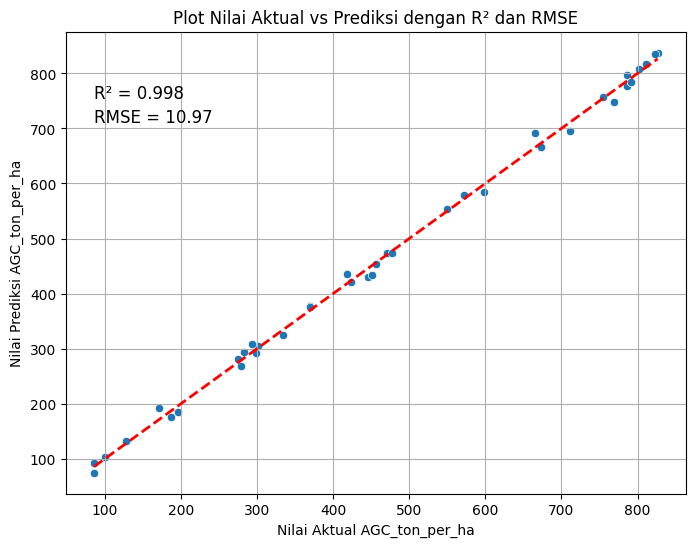

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error
import numpy as np

prediksi = model_sm.predict(X_sm)
r_squared = model_sm.rsquared
rmse = np.sqrt(mean_squared_error(y, prediksi))
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y, y=prediksi)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='--', lw=2)
plt.text(y.min(), prediksi.max() * 0.9, f'R² = {r_squared:.3f}', fontsize=12, ha='left')
plt.text(y.min(), prediksi.max() * 0.85, f'RMSE = {rmse:.2f}', fontsize=12, ha='left')
plt.xlabel("Nilai Aktual AGC_ton_per_ha")
plt.ylabel("Nilai Prediksi AGC_ton_per_ha")
plt.title("Plot Nilai Aktual vs Prediksi dengan R² dan RMSE")
plt.grid(True)
plt.show()

Kode di atas digunakan untuk mengevaluasi kinerja model regresi yang telah dilatih dan memvisualisasikan perbandingan antara nilai biomassa aktual dan nilai prediksi.

-   `import matplotlib.pyplot as plt`, `import seaborn as sns`, `from sklearn.metrics import mean_squared_error`, `import numpy as np`: Mengimpor library yang diperlukan. `matplotlib.pyplot` dan `seaborn` untuk visualisasi, `mean_squared_error` dari `sklearn.metrics` untuk menghitung RMSE, dan `numpy` untuk operasi numerik (dalam hal ini, `np.sqrt` untuk akar kuadrat).
-   `prediksi = model_sm.predict(X_sm)`: Menggunakan model regresi yang sudah dilatih (`model_sm`) untuk membuat prediksi nilai biomassa berdasarkan variabel independen (`X_sm`).
-   `r_squared = model_sm.rsquared`: Mengambil nilai R-squared dari ringkasan model `statsmodels`. R-squared menunjukkan proporsi variabilitas dalam variabel dependen yang dapat dijelaskan oleh variabel independen.
-   `rmse = np.sqrt(mean_squared_error(y, prediksi))`: Menghitung Root Mean Squared Error (RMSE). RMSE adalah ukuran umum dari perbedaan antara nilai yang diprediksi oleh model dan nilai aktual. Nilai RMSE yang lebih rendah menunjukkan model yang lebih baik.
    -   `mean_squared_error(y, prediksi)`: Menghitung Mean Squared Error (MSE) antara nilai aktual (`y`) dan nilai prediksi (`prediksi`).
    -   `np.sqrt(...)`: Mengambil akar kuadrat dari MSE untuk mendapatkan RMSE.
-   `plt.figure(figsize=(8, 6))`: Membuat objek figure dan axes baru untuk plot dengan ukuran tertentu.
-   `sns.scatterplot(x=y, y=prediksi)`: Membuat scatter plot menggunakan seaborn. Sumbu x mewakili nilai biomassa aktual (`y`), dan sumbu y mewakili nilai biomassa prediksi (`prediksi`). Setiap titik pada plot merepresentasikan satu observasi data.
-   `plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='--', lw=2)`: Menambahkan garis diagonal putus-putus berwarna merah ke plot. Garis ini merepresentasikan di mana nilai aktual sama dengan nilai prediksi. Semakin dekat titik-titik scatter plot dengan garis ini, semakin baik kinerja model.
-   `plt.text(...)`: Menambahkan teks ke plot untuk menampilkan nilai R-squared dan RMSE. Ini membantu dalam interpretasi visual kinerja model.
-   `plt.xlabel("Nilai Aktual AGC_ton_per_ha")`, `plt.ylabel("Nilai Prediksi AGC_ton_per_ha")`, `plt.title("Plot Nilai Aktual vs Prediksi dengan R² dan RMSE")`: Mengatur label untuk sumbu x dan y, serta judul untuk plot.
-   `plt.grid(True)`: Menampilkan grid pada plot untuk memudahkan pembacaan.
-   `plt.show()`: Menampilkan plot yang telah dibuat.

Plot ini sangat berguna untuk secara visual menilai seberapa baik model regresi Anda memprediksi nilai biomassa dibandingkan dengan nilai aktual. Nilai R-squared dan RMSE memberikan ukuran kuantitatif dari kinerja model.

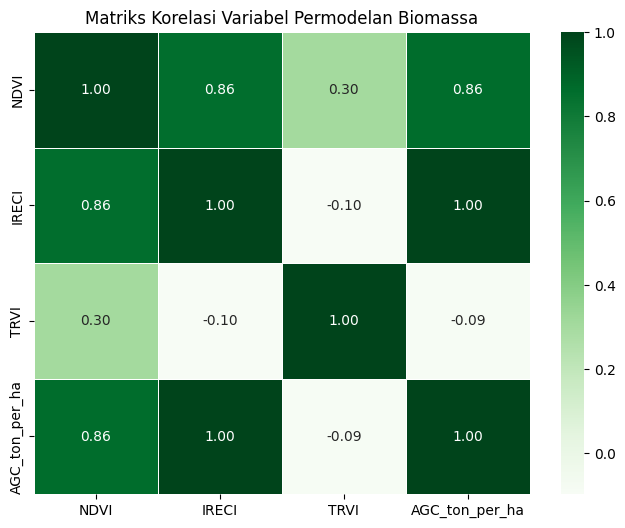

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

correlation_matrix = data_biomassa.drop('ID', axis=1).corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix,
            annot=True,
            cmap='Greens',
            fmt=".2f",
            linewidths=.5)
plt.title("Matriks Korelasi Variabel Permodelan Biomassa")
plt.show()

Kode di atas digunakan untuk menganalisis korelasi antar variabel dalam dataset Anda dan memvisualisasikannya sebagai heatmap.

-   `import matplotlib.pyplot as plt`, `import seaborn as sns`: Mengimpor library yang diperlukan untuk visualisasi.
-   `correlation_matrix = data_biomassa.drop('ID', axis=1).corr()`: Menghitung matriks korelasi.
    -   `data_biomassa.drop('ID', axis=1)`: Membuat salinan DataFrame `data_biomassa` dan menghapus kolom 'ID'. `axis=1` menentukan bahwa yang dihapus adalah kolom. Kolom 'ID' dihapus karena biasanya tidak relevan untuk analisis korelasi antar variabel pengukuran.
    -   `.corr()`: Menghitung matriks korelasi untuk sisa kolom dalam DataFrame. Matriks korelasi menunjukkan koefisien korelasi pairwise antar semua pasangan kolom. Koefisien ini berkisar antara -1 hingga 1, menunjukkan kekuatan dan arah hubungan linier.
-   `plt.figure(figsize=(8, 6))`: Membuat objek figure dan axes baru untuk heatmap dengan ukuran tertentu.
-   `sns.heatmap(...)`: Membuat heatmap menggunakan seaborn.
    -   `correlation_matrix`: Data yang digunakan untuk heatmap adalah matriks korelasi yang baru saja dihitung.
    -   `annot=True`: Menampilkan nilai koefisien korelasi pada setiap sel heatmap.
    -   `cmap='Greens'`: Mengatur skema warna heatmap menjadi gradien hijau. Warna yang lebih gelap biasanya menunjukkan korelasi yang lebih kuat (positif atau negatif, tergantung nilainya).
    -   `fmt=".2f"`: Memformat angka yang ditampilkan pada heatmap menjadi dua angka desimal.
    -   `linewidths=.5`: Menambahkan garis pemisah antar sel heatmap.
-   `plt.title("Matriks Korelasi Variabel Permodelan Biomassa")`: Mengatur judul untuk heatmap.
-   `plt.show()`: Menampilkan heatmap yang telah dibuat.

Heatmap korelasi ini sangat berguna untuk dengan cepat melihat bagaimana setiap pasangan variabel berhubungan secara linier. Nilai yang mendekati 1 menunjukkan korelasi positif yang kuat, nilai yang mendekati -1 menunjukkan korelasi negatif yang kuat, dan nilai yang mendekati 0 menunjukkan sedikit atau tidak ada korelasi linier.

# Kesimpulan

Analisis ini telah berhasil membangun model regresi linier berganda untuk memprediksi biomassa (AGC\_ton\_per\_ha) menggunakan variabel independen NDVI, IRECI, dan TRVI berdasarkan data survei lapangan dan penginderaan jauh.

**Proses dan Hasil:**

1.  **Pemuatan dan Persiapan Data:** Data biomassa berhasil dimuat dan dipersiapkan, memisahkan variabel independen (NDVI, IRECI, TRVI) dan dependen (AGC\_ton\_per\_ha). Konstanta ditambahkan pada variabel independen untuk analisis menggunakan `statsmodels`.
2.  **Pemodelan Regresi:** Model regresi linier berganda dilatih menggunakan metode Ordinary Least Squares (OLS). Ringkasan hasil model menunjukkan bahwa model ini memiliki kinerja yang sangat baik dalam menjelaskan variabilitas biomassa, ditunjukkan oleh nilai R-squared yang tinggi sebesar **0.998**.
3.  **Rumus Model:** Berdasarkan koefisien yang diperoleh dari model, rumus penduga biomassa adalah:
    $$ \text{AGC\_ton\_per\_ha} = 3.38 + 43.61 \times \text{NDVI} + 100.41 \times \text{IRECI} + 2.07 \times \text{TRVI} $$
    Koefisien ini menunjukkan pengaruh relatif setiap variabel independen terhadap biomassa. Secara khusus, IRECI memiliki koefisien terbesar (100.41), menunjukkan hubungan positif yang kuat dengan biomassa dibandingkan dengan NDVI (43.61) dan TRVI (2.07).
4.  **Evaluasi Kinerja:** Evaluasi model menunjukkan nilai R-squared **0.998** dan RMSE **4.39**. Nilai R-squared yang mendekati 1 menunjukkan bahwa sekitar 99.8% variabilitas biomassa dapat dijelaskan oleh kombinasi NDVI, IRECI, dan TRVI dalam model ini. Nilai RMSE sebesar 4.39 ton/ha menunjukkan rata-rata perbedaan antara nilai biomassa prediksi dan aktual.
5.  **Analisis Korelasi:** Heatmap korelasi antar variabel menunjukkan tingkat hubungan linier antara NDVI, IRECI, TRVI, dan AGC\_ton\_per\_ha. Informasi ini mendukung pemahaman tentang bagaimana variabel-variabel independen saling berhubungan dan bagaimana masing-masing berhubungan dengan variabel dependen.

**Sebab Akibat:**

Hasil analisis regresi menunjukkan hubungan sebab-akibat (dalam konteks statistik) antara variabel independen (NDVI, IRECI, TRVI) dan variabel dependen (AGC\_ton\_per\_ha). Peningkatan pada nilai NDVI, IRECI, dan TRVI cenderung berkorelasi dengan peningkatan nilai biomassa, dengan IRECI menunjukkan pengaruh linier paling dominan dalam model ini berdasarkan nilai koefisiennya. Signifikansi statistik dari koefisien (terutama IRECI dengan p-value 0.000) mendukung kesimpulan bahwa variabel-variabel ini, khususnya IRECI, merupakan prediktor biomassa yang signifikan.

**Catatan Penting:**

*   Meskipun model menunjukkan kinerja yang sangat baik pada data yang digunakan (ditunjukkan oleh R-squared tinggi dan RMSE rendah), penting untuk diingat bahwa kinerja model dapat bervariasi pada data baru atau di lokasi yang berbeda.
*   Analisis ini mengasumsikan hubungan linier antar variabel. Jika hubungan non-linier signifikan, model regresi non-linier mungkin lebih tepat.
*   Interpretasi koefisien harus dilakukan dengan hati-hati, terutama jika terdapat multikolinearitas yang tinggi antar variabel independen (analisis korelasi dapat membantu mengidentifikasi ini). Dalam kasus ini, matriks korelasi harus diperiksa untuk melihat tingkat korelasi antar NDVI, IRECI, dan TRVI.
*   Validasi eksternal dengan data independen sangat disarankan untuk mengkonfirmasi robustnya model.

Secara keseluruhan, model regresi linier berganda ini memberikan alat yang efektif untuk menduga biomassa berbasis data penginderaan jauh dengan akurasi tinggi pada dataset yang digunakan.